In [1]:
import pandas as pd
from numpy import nan
from helper_pandas import *
from unidecode import unidecode


import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud


from joblib import load

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,Judicial,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,Hospital,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


In [2]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'S-D':'#999999', 'S-D (DF)':'#d9d9d9', 'Masculino':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 
             'Feto':'#ff7f00', 
             'Miembros':'#f781bf', 
             'Restos óseos':'#c85a53', }

gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


## Diagnostico
'Diagnostico_transcrito', 
'Diagnostico_estandar',
'Diagnostico_extendido', 
'Diagnostico_clasificacion',


* red concurrencia
* por tipo restos,  edad,  sexo, procedencia
* tipo de restos, + procedencia alcaldia y unidad administrativa + diagnostico top
* tipo de restos + grupo edad y sexo + diagnostico
* centrar en cadaver conocido y desconocido
* comparar con tabla magica de los 60-80

Diagnóstico,  clasificación,  red concurrencia, por tipo restos,  edad,  sexo, procedencia

In [3]:
top_diag = df['Diagnostico_clasificacion'].value_counts().head(12)
# Filtrar diagnosticos clasificacion mas comunes, cadaveres, seco
df_diag = df[ df['Diagnostico_clasificacion'].isin(top_diag.index) ]
df_diag['Diagnostico_clasificacion'] = df_diag['Diagnostico_clasificacion'].cat.remove_unused_categories()
df_diag = df_diag[ df_diag['Tipo_restos']!='Restos óseos' ]
df_diag['Tipo_restos'] = df_diag['Tipo_restos'].cat.remove_unused_categories()
df_diag = df_diag[ df_diag['Sexo'].isin(['Femenino','Masculino']) ]
df_diag['Sexo'] = df_diag['Sexo'].cat.remove_unused_categories()
print(f"Diagnosticos alta frecuencia: {df_diag.shape[0]}/{df.shape[0]}\n")
top_diag

Diagnosticos alta frecuencia: 36330/96825



/tmp/ipykernel_22591/1514111589.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_diag['Diagnostico_clasificacion'] = df_diag['Diagnostico_clasificacion'].cat.remove_unused_categories()


Diagnostico_clasificacion
Trauma                                                                      20098
Causas externas de morbilidad y de mortalidad                                4466
Herida por arma de fuego                                                     3386
Enfermedades del sistema respiratorio                                        2423
Enfermedades del sistema digestivo                                           1672
Embarazo, parto y puerperio                                                  1260
Enfermedades del sistema circulatorio                                         976
Herida punzo cortante                                                         867
Amputación                                                                    697
Ciertas enfermedades infecciosas y parasitarias                               349
Enfermedades del sistema nervioso                                             114
Enfermedades del sistema digestivo+Enfermedades del sistema respiratorio

### Red de diagnósticos

In [4]:
import networkx as nx
from itertools import combinations


/tmp/ipykernel_22591/309252839.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


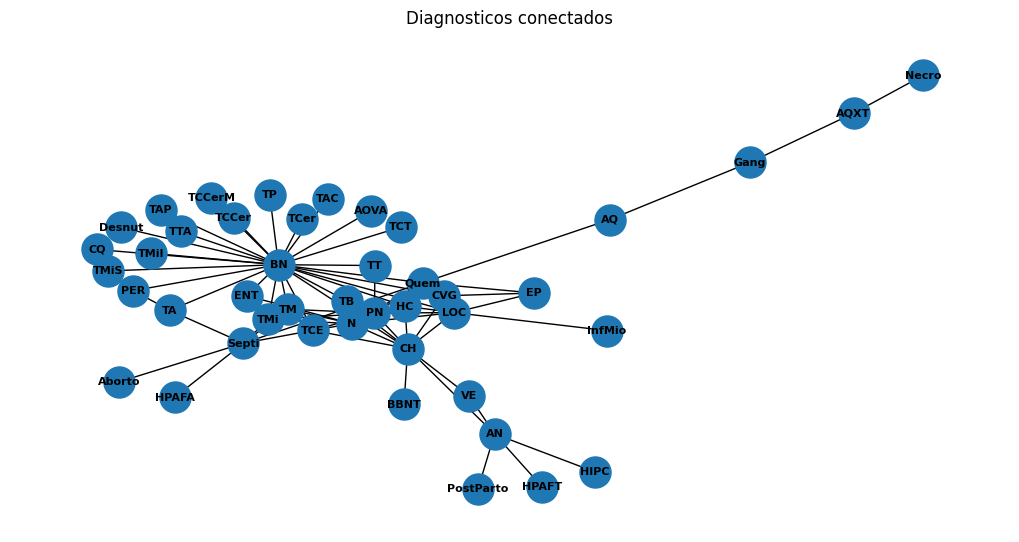

In [5]:
thr_node = 10

G = nx.Graph()
nodes = df['Diagnostico_estandar'].value_counts()
nodes = nodes[nodes>=10]
for node_name, weight in nodes.items():
    G.add_node(node_name, weight=weight)
#print(G.nodes(data=True))

edges = [i for i in nodes.index if '+' in i]
for e in edges:
    e = combinations(e.split('+'),2)
    for n1,n2 in e:
        if G.has_edge(n1, n2):
            w = G[n1][n2].get('weight', 0)
            G[n1][n2]['weight'] = w + 1
        else:
            G.add_edge(n1, n2, weight=1)
#print(G.edges(data=True))

# Remove isolated nodes
G_connected = G.copy()
isolated_nodes = list(nx.isolates(G_connected))
G_connected.remove_nodes_from(isolated_nodes)

# Plot the graph without isolated nodes
plt.figure(figsize=(10, 5))
nx.draw(G_connected, with_labels=True, 
        node_size=500, font_size=8, font_weight='bold')
plt.title("Diagnosticos conectados")

plt.tight_layout()
plt.show()

In [13]:
def export_networkx_to_yed(graph, filename):
    G = graph.copy()
    for node in G.nodes():
        if 'label' not in G.nodes[node]:
            G.nodes[node]['label'] = str(node)
        if 'weight' in G.nodes[node]:
            G.nodes[node]['node_weight'] = int(G.nodes[node]['weight'])
    for u, v in G.edges():
        if 'weight' in G.edges[u, v]:
            #G.edges[u, v]['label'] = str(G.edges[u, v]['weight'])
            G.edges[u, v]['edge_weight'] = int(G.edges[u, v]['weight'])
    nx.write_graphml(G, filename)
export_networkx_to_yed(G, 'data_clean/HBO_diag_graph.graphml')

### Diagnóstico por sexo

In [7]:
data = df_diag.pivot_table(
    index='Diagnostico_clasificacion',
    columns=['Tipo_restos','Sexo'],
    values='Diagnostico_estandar',
    aggfunc=top_values_of_series_to_string
)
pd.concat([data,top_diag], axis=1).sort_values('count', ascending=False)

/tmp/ipykernel_22591/1681653258.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  data = df_diag.pivot_table(


,"(Cadáver conocido, Femenino)","(Cadáver conocido, Masculino)","(Cadáver desconocido, Femenino)","(Cadáver desconocido, Masculino)","(Recién nacido, Femenino)","(Recién nacido, Masculino)","(Feto, Femenino)","(Feto, Masculino)","(Miembros, Femenino)","(Miembros, Masculino)",count
Diagnostico_clasificacion,,,,,,,,,,,
Trauma,"TM (1542), TCE (1098), TCT (248), BN+TMi (98),...","TM (4545), TCE (4090), TCT (781), BN+TCE (495)...","TM (202), TCE (81), TCT (15), TTA (7), TAC (6)","TM (1224), TCE (693), TCT (141), BN+TCE (47), ...","TCE (7), TM (2), TCTA (1), TTA (1), Hemo+Pancr...","TCE (6), TM (5), TCMT (1), TCEA (1), TCCerM (1)","TCE (7), TM+Utero (1), TCCerM (1), TM (1), TMi...","TCE (6), TM (3), TCTA (1), Materno+Trau (1), T...","TMi (7), TMiS+_Ins (1), TMiS (1), Hemo+Intra (...","TMi (26), Trau (2), TMiS (2), O+TA (1), Hemo+L...",20098
Causas externas de morbilidad y de mortalidad,"Quem (257), HC (185), AOVA (165), BN+Quem (140...","AOVA (513), Quem (477), AXA (448), ASB (354), ...","Quem (19), AOVA (17), AE (16), ASB (11), HC (11)","AOVA (107), ASB (69), Quem (57), AXA (33), HC ...","AE (6), Anoxia (3), AOVA (1), Quem (1), HC (1)","AE (10), AOVA (3), AXA (2), AXA+OVAR (1), AN+H...","Anoxia (2), ASB (2), AE (2), AOVA (1), Anoxia+...","Anoxia (7), AE (4), AXA (1), Anoxia+PostT (1),...","Quem (2), AOVA+MordCan (1), AOVA+HC (1), Hemo+...","Electroc (6), AOVA+Quem (4), Quem (3), AOVA+El...",4466
Herida por arma de fuego,"HPAFC (116), HPAF (69), HPAFPT (48), HPAFA (31...","HPAF (845), HPAFC (752), HPAFPT (504), HPAFA (...","HPAF (11), HPAFC (7), HPAFTV (1), HPAFCTA (1),...","HPAF (72), HPAFC (68), HPAFPT (48), HPAFA (14)...",NaN,"HPAFA (1), Hemo+Pancrea (0), Hemo+Post (0), He...",NaN,"HPAF (1), Hemo+Pancrea (0), Hemo+Post (0), Hem...",NaN,"HPAF (3), HPAF+Izquemia (1), Extox+HPAF (1), H...",3386
Enfermedades del sistema respiratorio,"BN (400), PN (32), N (28), EP (14), BBNT (11)","BN (747), PN (105), N (70), EP (29), InfPul (22)","BN (98), PN (6), N (4), BBNT (3), ANE+N (1)","BN (576), PN (90), N (26), BBNT (11), InfPul (4)","BN (10), EP (1), Hemo+PER+SH+Septi+TP (0), Hem...","BN (19), H+N+NE (1), BBNT (1), Hemo+PostParto+...","EP+PSM (1), BN (1), PN (1), N (1), Hemo+PER+SH...","BN (3), EP+SM (3), EP+PSM (2), Hemo+Post (0), ...",NaN,NaN,2423
Enfermedades del sistema digestivo,"BN+CH (54), BN+ENT (34), CH (22), Gastroent (1...","BN+CH (320), CH+PN (84), CH (71), BN+ENT (59),...","BN+CH (39), BN+ENT (17), CH+PN (4), CH (3), CH...","BN+CH (386), CH+PN (86), CH (62), BN+ENT (22),...","BN+ENT (2), CH+Falta+PostN (1), Hemo+Pancrea (...","BN+ENT (5), Hernia+_Bockdebe (1), ENT (1), Hem...",NaN,"BN+ENT (1), BN+CH (1), ENT+Gral+Mal (1), Hemo+...",NaN,NaN,1672
"Embarazo, parto y puerperio","Aborto+Septi (20), AN+PostParto (16), Aborto (...","ANEN (8), AN+PostParto (1), AN+Parto (1), FCPN...","ANEN (6), EXPSM (3), FCPN (3), EXPSM+P (2), EX...","ANEN (16), EXPSM (4), EXPSM+P (3), Fetal+Sufri...","ANEN (40), FCPN (3), AXAS+PostParto (1), EXPSM...","ANEN (35), FCPN (2), Hemo+PER+SH+Septi+TP (0),...","ANEN (196), EXPSM (186), FCPN (11), Fetal+Suri...","EXPSM (304), ANEN (257), FCPN (6), Fdesarrollo...",NaN,NaN,1260
Enfermedades del sistema circulatorio,"LOC (123), BN+LOC (18), InfMio+LOC (14), CVG+L...","LOC (444), BN+LOC (75), CVG+LOC (32), InfMio+L...","LOC (11), BN+LOC (3), CVG+LOC (3), LOC+PN (1),...","LOC (93), BN+LOC (21), InfMio+LOC (6), CVG+LOC...",NaN,"LOC (1), Hemo+PER+SH+Septi+TP (0), Hemo+Pancre...",NaN,NaN,NaN,"Trombo (2), Oclusion (1), IP+LOC (1), Hepat+TC...",976
Herida punzo cortante,"HIPC (21), HIPCT (11), HIPCTA (9), AN+HIPC (5)...","HIPCT (236), HIPC (215), HIPCTA (69), HIPCPA (...","HIPCT (1), HIPC (1), Hemo+Pancrea (0), Hemo+Po...","HIPCT (39), HIPC (23), HIPCTA (15), HIPCPA (6)...",NaN,"HIPCC (1), HIPC (1), Hemo+PER+SH+Septi+TP (0),...",NaN,NaN,NaN,NaN,867
Amputación,"AQXT (2), AQXTMi+BN (1), Hemo+Pancrea (0), Hem...","AQXT (7), AQ (2), AAH+AT (1), AQXTMi+BN (1), A...",NaN,"AQXT (1), AQ+MI+SH (1), Hemo+PER+SH+Septi+TP (...",NaN

In [8]:
col_tran = [c for c in df_diag.columns if 'transcrito' in c]
df_diag.loc[(df_diag['Diagnostico_clasificacion']=='Embarazo, parto y puerperio')&(df_diag['Sexo']=='Masculino'), col_tran]

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Fecha_transcrito,Edad_transcrito,Diagnostico_transcrito,Procedencia_transcrito,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Foja_transcrito
ID,,,,,,,,,
BO_1974_03518,S-D,parkansi flores,1974-08-30,5 días,ANN,19a,755,4129,70
BO_1974_03633,20,quinino medina sin nombre,1974-09-04,[8],ANEN,27a,646,4244,73
BO_1974_04767,341,desconocido,1974-06-08,7.5,ANN,15a,1351,2776,115
BO_1974_05303,6,feto,1974-01-12,5 meses,EX PSM,20a,26,191,140
BO_1974_05304,7,feto,1974-01-14,9 meses,ANN,9a,65,212,140
...,...,...,...,...,...,...,...,...,...
BO_1979_07196,S-D,recien nacido,1979-01-25,-72,ANEN,35a,159,515,145
BO_1979_07206,S-D,recien nacido,1979-04-29,-72,ANEN,24a,1050,2418,145
BO_1979_07209,S-D,nombre confidencial,1979-05-29,-72,ANEON,1a,1793,3032,145


/tmp/ipykernel_22591/247179990.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns=['Tipo_restos','Sexo'], values='Diagnostico_estandar', aggfunc='count')


Text(0.5, 1.0, 'Ingresos por diagnóstico, tipo restos y sexo')

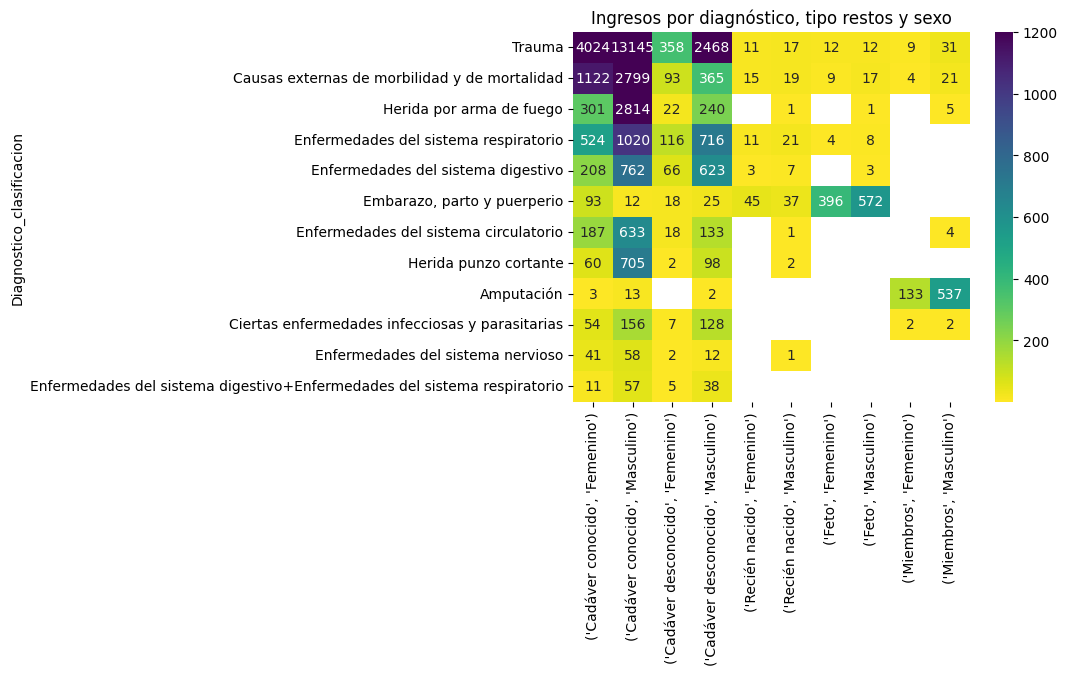

In [9]:
from matplotlib.colors import LogNorm

data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns=['Tipo_restos','Sexo'], values='Diagnostico_estandar', aggfunc='count')
data = pd.concat([data,top_diag], axis=1).sort_values('count', ascending=False) \
         .drop(['count'], axis=1).replace({0:nan})
plt.figure()
sns.heatmap(data, cmap='viridis_r', annot=data, fmt='.0f', vmax=1200)
plt.title('Ingresos por diagnóstico, tipo restos y sexo')

/tmp/ipykernel_22591/457396160.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns=['Tipo_restos','Sexo'], values='Diagnostico_estandar', aggfunc='count')


Text(0.5, 1.0, 'Ingresos por diagnóstico, tipo restos y sexo\n(Porcentaje por columna)')

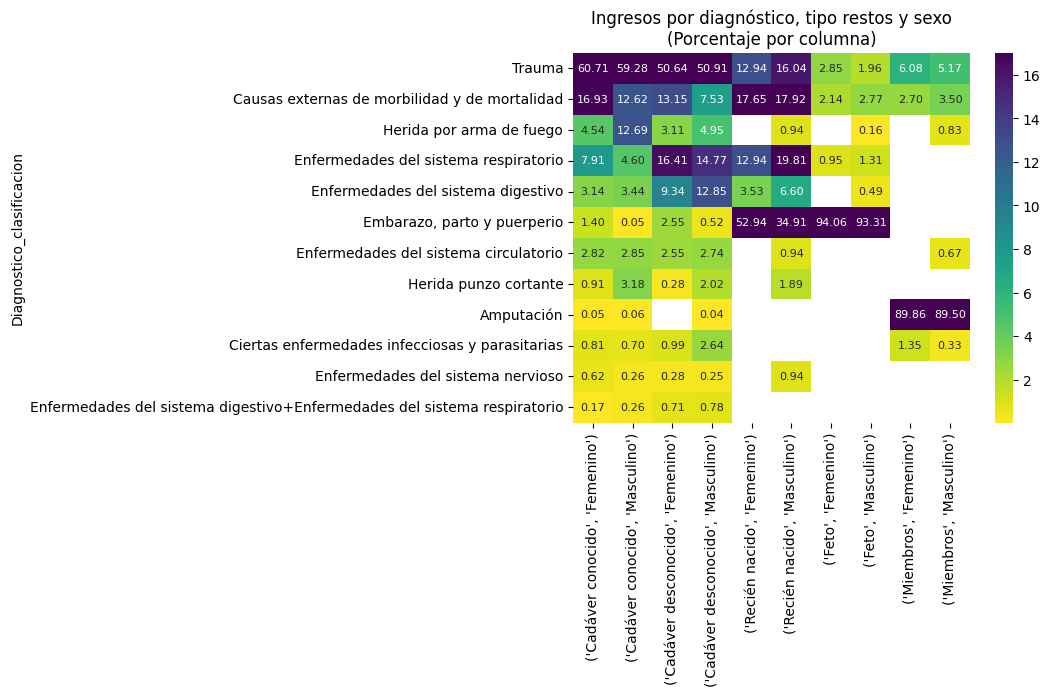

In [10]:
from matplotlib.colors import LogNorm

data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns=['Tipo_restos','Sexo'], values='Diagnostico_estandar', aggfunc='count')
data = pd.concat([data,top_diag], axis=1).sort_values('count', ascending=False) \
         .drop(['count'], axis=1).replace({0:nan})
data_ = data/data.sum()*100
plt.figure()
sns.heatmap(data_, cmap='viridis_r', vmax=17, annot=data_, annot_kws={'size': 8}, fmt='.2f')
plt.title('Ingresos por diagnóstico, tipo restos y sexo\n(Porcentaje por columna)')